# Target and dataset 

* This notebook shows the data used in every research question. It only reads saved files.(not build),
* Data Setup is in scr and test folder 

In [9]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# The project folder, whether the notebook runs from notebooks/ or from the project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

target = pd.read_csv(ROOT / "data" / "processed" / "target.csv")
dataset = pd.read_csv(ROOT / "data" / "processed" / "dataset.csv")
print("target.csv: ", len(target), "months,", target["month"].iloc[0], "to", target["month"].iloc[-1])
print("dataset.csv:", len(dataset), "months,", dataset.shape[1] - 2, "predictors")

target.csv:  248 months, 2006-01 to 2026-08
dataset.csv: 248 months, 24 predictors


## 1. The target: official vs adjusted

* Both series exclude fresh food and energy (core-core CPI). 
* The target is the official adjusted series: They remove consumption-tax rises and, from 2016, free education, travel subsidies and the 2021 mobile-phone fee cut. 
- Both series is from BOJ and Statistics Bureau We change no number ourselves. can refer [data/README.md]

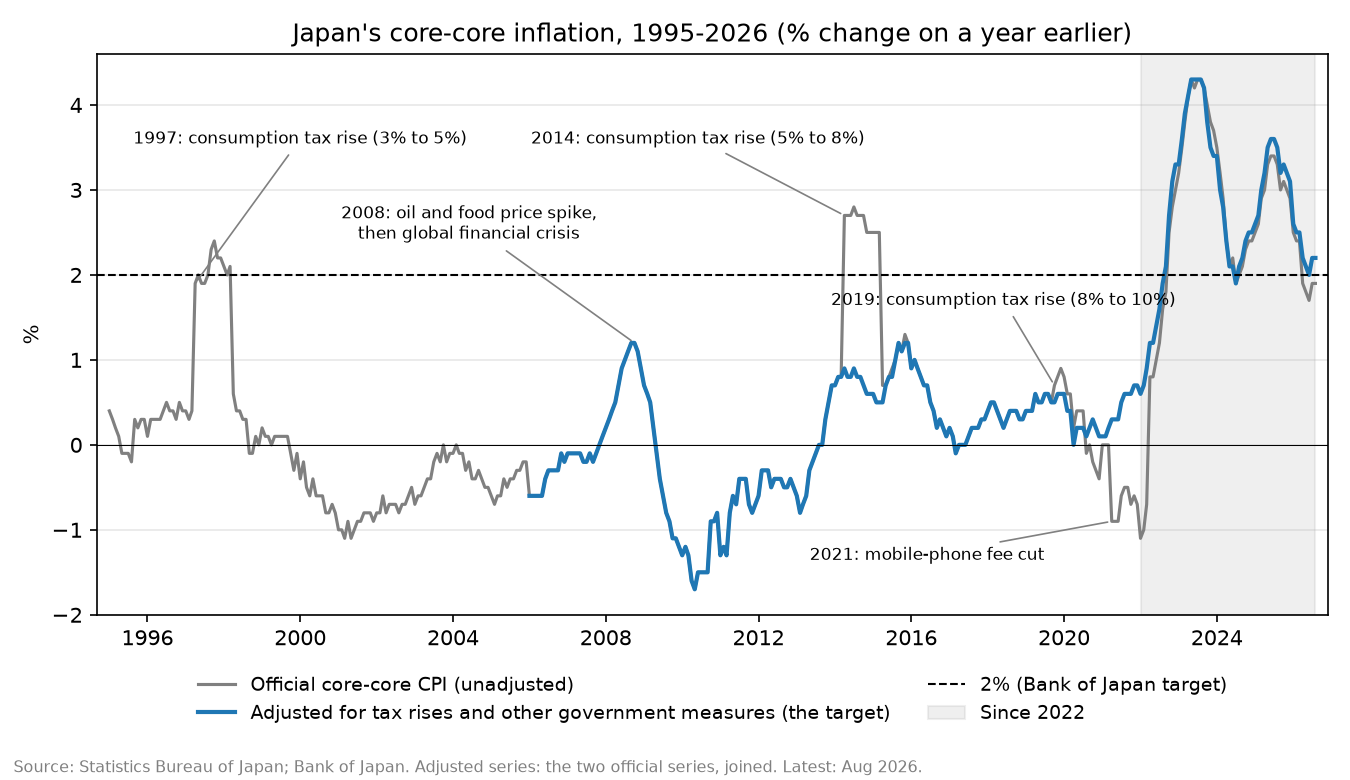

In [10]:
display(Image(filename=str(ROOT / "results" / "figures" / "core_core_inflation_light.png"), width=800))

## 2. Where the target differs from the official series

* Each difference is an adjustment made by the Statistics Bureau or the Bank of Japan. 
* The first row is the exception: free high-school tuition in Apr 2010 to Mar 2011 lowered inflation by about 0.5 points, but neither source removes it, so the difference is 0.

In [11]:
check = target.set_index("month").loc[["2010-04", "2014-04", "2020-12", "2021-04", "2026-08"], ["official", "target"]]
check["difference"] = (check["target"] - check["official"]).round(1)
check["reason"] = [
    "Free high-school tuition 2010: not removed",
    "Consumption tax rise, 5% to 8%",
    "Travel subsidies (Go To Travel)",
    "Mobile-phone fee cut",
    "Free high-school tuition and school lunches",
]
check

,official,target,difference,reason
month,,,,
2010-04,-1.6,-1.6,0.0,Free high-school tuition 2010: not removed
2014-04,2.7,0.9,-1.8,"Consumption tax rise, 5% to 8%"
2020-12,-0.4,0.1,0.5,Travel subsidies (Go To Travel)
2021-04,-0.9,0.3,1.2,Mobile-phone fee cut
2026-08,1.9,2.2,0.3,Free high-school tuition and school lunches


## 3. Average inflation in each period

These are the periods used in RQ2: the first training window, then the two scored periods.

In [12]:
periods = {
    "2007-2012 (first training window)": ("2007-01", "2012-12"),
    "2013-2021": ("2013-01", "2021-12"),
    "2022-Aug 2026": ("2022-01", "2026-08"),
}
rows = []
for name, (first, last) in periods.items():
    part = target[(target["month"] >= first) & (target["month"] <= last)]
    rows.append({"period": name, "months": len(part),
                 "target": round(part["target"].mean(), 2), "official": round(part["official"].mean(), 2)})
pd.DataFrame(rows)

,period,months,target,official
0,2007-2012 (first training window),72,-0.36,-0.36
1,2013-2021,108,0.41,0.52
2,2022-Aug 2026,56,2.75,2.54


## 4. The 24 predictors

* 18 are based on the IMF paper's predictors, and 6 are our own. The first part of each name is its economic channel (c1 to c8). 
* 23 are published series or their % change on a year earlier. One is calculated by us: `c1_hh_expect_cp` by using Carlso-Parkin in a BOJ survey data
* Each predictor's full description is in `src/build_dataset.py`, in the list called `PREDICTORS`.

In [13]:
CHANNELS = {
    "c1": "Inflation expectations",
    "c2": "Exchange rate and business costs",
    "c3": "Food costs",
    "c4": "Slack and demand",
    "c5": "Wages",
    "c6": "Firms' price-setting",
    "c7": "Tourism",
    "c8": "Financial conditions",
}
OURS = ["c3_food_import", "c3_food_ppi", "c5_shunto",
        "c6_tankan_all", "c6_tankan_small_services", "c6_diffusion"]

names = [c for c in dataset.columns if c not in ("month", "target")]
predictors = pd.DataFrame({"name": names})
predictors["channel"] = predictors["name"].str[:2].map(CHANNELS)
predictors["origin"] = ["ours" if n in OURS else "IMF-based" for n in names]

assert len(names) == 24 and predictors["channel"].notna().all()
print(predictors["origin"].value_counts().to_dict())
predictors

{'IMF-based': 18, 'ours': 6}


,name,channel,origin
0,c1_hh_expect_mean,Inflation expectations,IMF-based
1,c1_hh_expect_cp,Inflation expectations,IMF-based
2,c2_usdjpy,Exchange rate and business costs,IMF-based
3,c2_import_prices,Exchange rate and business costs,IMF-based
4,c2_energy_import,Exchange rate and business costs,IMF-based
5,c2_ppi,Exchange rate and business costs,IMF-based
6,c2_sppi,Exchange rate and business costs,IMF-based
7,c3_food_import,Food costs,ours
8,c3_food_ppi,Food costs,ours
9,c4_output_gap,Slack and demand,IMF-based


## 5. Summary statistics, Jan 2007 to Aug 2026

This can be Table 1 in the paper. `count` is below 236 only where a series has missing months.

In [14]:
sample = dataset[dataset["month"] >= "2007-01"]
columns = ["target"] + names
sample[columns].describe().T[["count", "mean", "std", "min", "max"]].round(2)

,count,mean,std,min,max
target,236.0,0.73,1.35,-1.70,4.30
c1_hh_expect_mean,236.0,5.71,3.02,1.70,13.10
c1_hh_expect_cp,236.0,2.28,0.94,0.35,4.55
c2_usdjpy,236.0,2.04,10.34,-18.77,30.13
c2_import_prices,236.0,3.54,15.73,-34.79,49.47
c2_energy_import,236.0,9.69,38.30,-53.52,133.30
c2_ppi,236.0,1.42,3.74,-8.66,10.61
c2_sppi,236.0,0.61,1.35,-2.28,3.65
c3_food_import,236.0,4.84,11.42,-27.14,32.09
c3_food_ppi,236.0,1.97,2.48,-2.82,8.93


## 6. Missing values from Jan 2007

The tourist series ends in June 2026, because that is the last month in the JNTO file. Download it again before the final run.

In [15]:
missing = sample[columns].isna().sum()
missing[missing > 0]

c7_tourists    2
dtype: int64

## 7. Publication delays: each value is used only once it is published

- Unemployment: August's rate comes out after the forecast date, so August 2026 holds July's rate.
- Shunto: the 2026 settlement enters in August.
- Tankan: the BOJ files the June survey's forecast under September, so it is known from June.

In [16]:
dataset.set_index("month").loc[["2026-06", "2026-07", "2026-08"],
                                ["c4_unemployment", "c5_shunto", "c6_tankan_all", "c1_hh_expect_mean"]]

,c4_unemployment,c5_shunto,c6_tankan_all,c1_hh_expect_mean
month,,,,
2026-06,2.5,5.52,45.0,13.1
2026-07,2.5,5.52,45.0,13.1
2026-08,2.4,5.18,45.0,13.1
